# Sales Performance Analysis - End-to-End Case Study
**Beeskilled x Axcentra Internship - Week 4 Capstone**

**Business question:** *Where does the company make (and lose) money, and what should leadership do about it?*

**Dataset:** 700 sales records · 5 segments · 5 countries · 6 products · Sep 2013 - Dec 2014

**Workflow:** 1. Clean & explore (Python) → 2. Analyse (Pandas + SQL) → 3. Visualise (Excel + Power BI) → 4. Report & recommendations

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mt, seaborn as sns
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
M = mt.FuncFormatter(lambda x,_: f'${x/1e6:.0f}M' if abs(x)>=1e6 else f'${x/1e3:.0f}K')
df = pd.read_excel('../01_Data/Sample_data_raw.xlsx')
print(df.shape); df.head()

(700, 16)


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,"1,513.00",3,350,"529,550.00",0.00,"529,550.00","393,380.00","136,170.00",2014-12-01,12,December,2014
1,Government,Germany,Paseo,NaN,"1,006.00",10,350,"352,100.00",0.00,"352,100.00","261,560.00","90,540.00",2014-06-01,6,June,2014
2,Government,Canada,Paseo,NaN,"1,725.00",10,350,"603,750.00",0.00,"603,750.00","448,500.00","155,250.00",2013-11-01,11,November,2013
3,Government,Germany,Paseo,NaN,"1,513.00",10,350,"529,550.00",0.00,"529,550.00","393,380.00","136,170.00",2014-12-01,12,December,2014
4,Government,Germany,Velo,NaN,"1,006.00",120,350,"352,100.00",0.00,"352,100.00","261,560.00","90,540.00",2014-06-01,6,June,2014


## 1. Data Cleaning & Quality Checks

In [2]:
df.info()
print('\nMissing values:\n', df.isna().sum()[df.isna().sum()>0])
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    str           
 1   Country              700 non-null    str           
 2   Product              700 non-null    str           
 3   Discount Band        647 non-null    str           
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9    Sales               700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[us]
 13  Month Number         700 non-null    int64    

**Issues found & how they were handled**
| # | Issue | Fix |
|---|---|---|
| 1 | Column `' Sales'` has a leading space | Stripped; spaces → underscores |
| 2 | `Discount Band` blank in 53 rows | All 53 have `Discounts = 0` → they are *no-discount* sales, relabelled **"No Discount"** (not dropped) |
| 3 | 36 rows have half units (e.g. 4492.5) | Kept as reported; flagged for the data owner |
| 4 | `Manufacturing Price` does not reconcile to COGS ÷ Units | COGS used as reported for profit; flagged as a data-governance issue |
| 5 | Only Sep-Dec in 2013 vs full-year 2014 | Year-over-year comparisons are done **like-for-like (Sep-Dec only)** |

In [3]:
df.columns = df.columns.str.strip().str.replace(' ','_')
df['Discount_Band'] = df['Discount_Band'].fillna('No Discount')
assert (df.loc[df.Discount_Band=='No Discount','Discounts']==0).all()      # blanks really mean no discount
assert (df.Gross_Sales-df.Discounts-df.Sales).abs().max()<0.01             # Gross - Discounts = Sales
assert (df.Sales-df.COGS-df.Profit).abs().max()<0.01                       # Sales - COGS = Profit
df['Date']=pd.to_datetime(df['Date'])
df['Profit_Margin_Pct']=(df.Profit/df.Sales*100).round(2)
df['Discount_Pct']=(df.Discounts/df.Gross_Sales*100).round(2)
df['Year_Month']=df.Date.dt.strftime('%Y-%m')
df['Loss_Making']=(df.Profit<0).astype(int)
print('Clean data OK - financial identities validated on all 700 rows')
df.describe().T

Clean data OK - financial identities validated on all 700 rows


,count,mean,min,25%,50%,75%,max,std
Units_Sold,700.00,"1,608.29",200.00,905.00,"1,542.50","2,229.12","4,492.50",867.43
Manufacturing_Price,700.00,96.48,3.00,5.00,10.00,250.00,260.00,108.60
Sale_Price,700.00,118.43,7.00,12.00,20.00,300.00,350.00,136.78
Gross_Sales,700.00,"182,759.43","1,799.00","17,391.75","37,980.00","279,025.00","1,207,500.00","254,262.28"
Discounts,700.00,"13,150.35",0.00,800.32,"2,585.25","15,956.34","149,677.50","22,962.93"
Sales,700.00,"169,609.07","1,655.08","15,928.00","35,540.20","261,077.50","1,159,200.00","236,726.35"
COGS,700.00,"145,475.21",918.00,"7,490.00","22,506.25","245,607.50","950,625.00","203,865.51"
Profit,700.00,"24,133.86","-40,617.50","2,805.96","9,242.20","22,662.00","262,200.00","42,760.63"
Date,700,2014-04-28 21:36:00,2013-09-01 00:00:00,2013-12-24 06:00:00,2014-05-16 12:00:00,2014-09-08 12:00:00,2014-12-01 00:00:00,NaN
Month_Number,700.00,7.90,1.00,5.75,9.00,10.25,12.00,3.38


## 2. Headline KPIs

In [4]:
k = dict(Net_Sales=df.Sales.sum(), Profit=df.Profit.sum(), Margin_pct=df.Profit.sum()/df.Sales.sum()*100,
         Units=df.Units_Sold.sum(), Discounts_Given=df.Discounts.sum(), Loss_Making_Orders=df.Loss_Making.sum())
pd.Series(k).to_frame('Value')

,Value
Net_Sales,"118,726,350.26"
Profit,"16,893,702.26"
Margin_pct,14.23
Units,"1,125,806.00"
Discounts_Given,"9,205,248.24"
Loss_Making_Orders,58.00


## 3. Segment, Country & Product Analysis

In [5]:
def summarize(by):
    g=df.groupby(by).agg(Sales=('Sales','sum'),Profit=('Profit','sum'),Units=('Units_Sold','sum'),Discounts=('Discounts','sum'),Gross=('Gross_Sales','sum'),Orders=('Sales','size'))
    g['Margin_%']=(g.Profit/g.Sales*100).round(1); g['Profit_Share_%']=(g.Profit/g.Profit.sum()*100).round(1)
    return g.sort_values('Sales',ascending=False).drop(columns='Gross')
seg=summarize('Segment'); seg

,Sales,Profit,Units,Discounts,Orders,Margin_%,Profit_Share_%
Segment,,,,,,,
Government,"52,504,260.67","11,388,173.17","470,673.50","3,898,805.83",300,21.70,67.40
Small Business,"42,427,918.50","4,143,168.50","153,139.00","3,513,781.50",100,9.80,24.50
Enterprise,"19,611,694.38","-614,545.62","168,552.00","1,457,305.62",100,-3.10,-3.60
Midmarket,"2,381,883.08","660,103.07","172,178.00","200,786.92",100,27.70,3.90
Channel Partners,"1,800,593.64","1,316,803.14","161,263.50","134,568.36",100,73.10,7.80


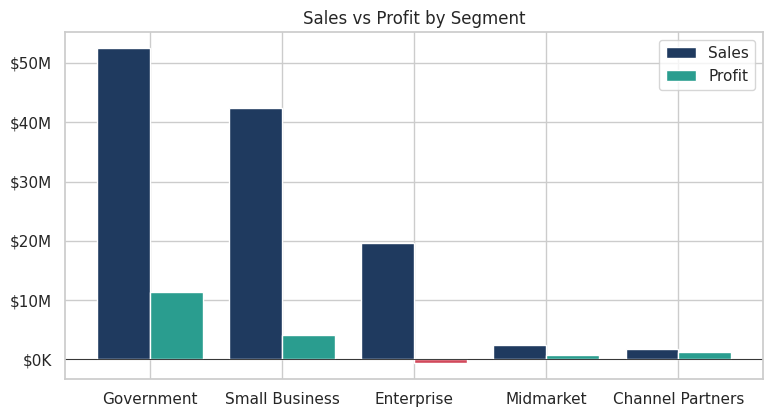

In [6]:
fig,ax=plt.subplots(figsize=(9,4.5)); s=seg.reset_index(); x=np.arange(len(s))
ax.bar(x-.2,s.Sales,.4,label='Sales',color='#1F3A5F'); ax.bar(x+.2,s.Profit,.4,label='Profit',color=['#2A9D8F' if v>=0 else '#D1495B' for v in s.Profit])
ax.set_xticks(x); ax.set_xticklabels(s.Segment); ax.yaxis.set_major_formatter(M); ax.axhline(0,color='k',lw=.6); ax.legend(); ax.set_title('Sales vs Profit by Segment'); plt.show()

**Insight 1:** Government delivers **67% of all profit**. Enterprise is the 3rd-largest segment by sales ($19.6M) but is **loss-making (-$0.6M)**. Channel Partners earn a 73% margin but are only 1.5% of sales.

In [7]:
summarize('Country')

,Sales,Profit,Units,Discounts,Orders,Margin_%,Profit_Share_%
Country,,,,,,,
United States of America,"25,029,830.16","2,995,540.67","232,627.50","2,239,527.83",140,12.00,17.70
Canada,"24,887,654.89","3,529,228.89","247,428.50","2,044,508.61",140,14.20,20.90
France,"24,354,172.28","3,781,020.78","240,931.00","1,727,502.22",140,15.50,22.40
Germany,"23,505,340.82","3,680,388.82","201,494.00","1,416,126.68",140,15.70,21.80
Mexico,"20,949,352.11","2,907,523.11","203,325.00","1,777,582.89",140,13.90,17.20


In [8]:
summarize('Product')

,Sales,Profit,Units,Discounts,Orders,Margin_%,Profit_Share_%
Product,,,,,,,
Paseo,"33,011,143.95","4,797,437.95","338,239.50","2,600,518.05",202,14.50,28.40
VTT,"20,511,921.02","3,034,608.02","168,783.00","1,456,612.48",109,14.80,18.00
Velo,"18,250,059.46","2,305,992.46","162,424.50","1,576,709.03",109,12.60,13.70
Amarilla,"17,747,116.06","2,814,104.06","155,315.00","1,290,163.44",94,15.90,16.70
Montana,"15,390,801.88","2,114,754.88","154,198.00","1,159,032.62",93,13.70,12.50
Carretera,"13,815,307.88","1,826,804.89","146,846.00","1,122,212.61",93,13.20,10.80


**Insight 2:** Countries and products are fairly balanced (margins 12-16%) - the real profit differences are driven by **Segment and Discount**, not geography or product.

## 4. Discount Analysis - the key profit driver

In [9]:
order=['No Discount','Low','Medium','High']
band=summarize('Discount_Band').loc[order]; band['Avg_Discount_%']=(band.Discounts/df.groupby('Discount_Band').Gross_Sales.sum().loc[order]*100).round(1); band

,Sales,Profit,Units,Discounts,Orders,Margin_%,Profit_Share_%,Avg_Discount_%
Discount_Band,,,,,,,,
No Discount,"7,943,654.00","1,736,455.00","86,163.50",0.00,53,21.90,10.30,0.00
Low,"34,629,778.70","6,188,857.70","261,858.50","885,675.80",160,17.90,36.60,2.50
Medium,"38,780,430.84","5,579,522.83","379,698.50","3,002,546.17",242,14.40,33.00,7.20
High,"37,372,486.73","3,388,866.73","398,085.50","5,317,026.28",245,9.10,20.10,12.50


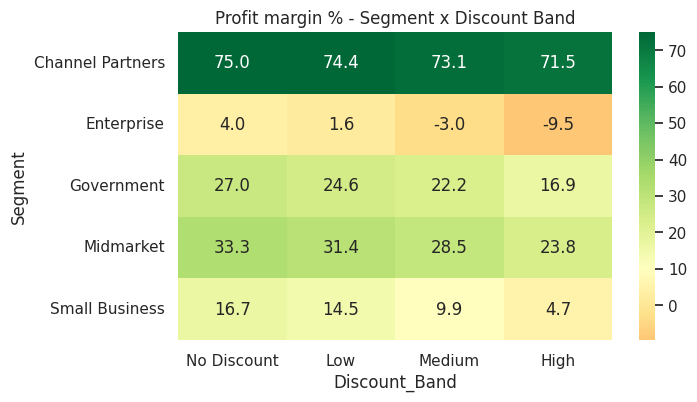

In [10]:
hm=df.groupby(['Segment','Discount_Band'])[['Profit','Sales']].sum().assign(m=lambda x:x.Profit/x.Sales*100)['m'].unstack()[order]
plt.figure(figsize=(7,4)); sns.heatmap(hm,annot=True,fmt='.1f',cmap='RdYlGn',center=10); plt.title('Profit margin % - Segment x Discount Band'); plt.show()

**Insight 3:** Margin falls steadily as discounts deepen: **21.9% → 17.9% → 14.4% → 9.1%**. Every segment follows the pattern.

**Insight 4 - Enterprise problem:** list price \$125 vs cost \$120/unit → only **4% gross margin before discounts**. With an average ~6.9% discount, every Enterprise order with a Medium/High discount loses money (58 orders, all Enterprise).

In [11]:
ent=df[df.Segment=='Enterprise']
print('Enterprise gross margin before discount: %.1f%%' % ((ent.Gross_Sales.sum()-ent.COGS.sum())/ent.Gross_Sales.sum()*100))
print('Enterprise actual profit        : $%s' % f'{ent.Profit.sum():,.0f}')
print('Enterprise profit if no discount: $%s  (upper bound - assumes same volume)' % f'{ent.Profit.sum()+ent.Discounts.sum():,.0f}')
df[df.Loss_Making==1].groupby(['Segment','Discount_Band']).agg(Orders=('Profit','size'),Loss=('Profit','sum'))

Enterprise gross margin before discount: 4.0%
Enterprise actual profit        : $-614,546
Enterprise profit if no discount: $842,760  (upper bound - assumes same volume)


Orders        Loss
Segment    Discount_Band                    
Enterprise High               33 -622,368.75
           Medium             25 -154,952.50

## 5. Time-Series Analysis

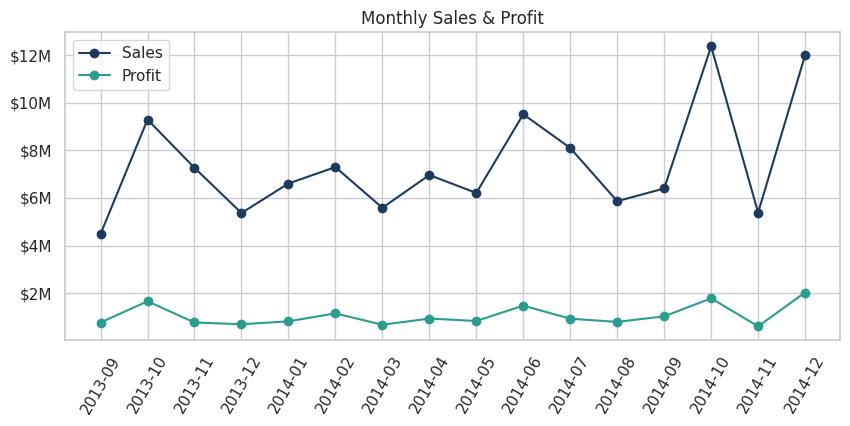

,Sales,Profit
Year,,
2013,"26,415,255.51","3,878,464.51"
2014,"36,157,519.26","5,435,484.26"
Growth %,36.88,40.15


In [12]:
month=df.groupby('Year_Month').agg(Sales=('Sales','sum'),Profit=('Profit','sum'))
month['MoM_Growth_%']=(month.Sales.pct_change()*100).round(1)
fig,ax=plt.subplots(figsize=(10,4)); ax.plot(month.index,month.Sales,marker='o',label='Sales',color='#1F3A5F'); ax.plot(month.index,month.Profit,marker='o',label='Profit',color='#2A9D8F')
ax.yaxis.set_major_formatter(M); plt.xticks(rotation=60); ax.legend(); ax.set_title('Monthly Sales & Profit'); plt.show()
like=df[df.Date.dt.month>=9].groupby('Year')[['Sales','Profit']].sum(); like.loc['Growth %']=(like.loc[2014]/like.loc[2013]-1)*100; like

**Insight 5:** Like-for-like (Sep-Dec), **sales grew +36.9% and profit +40.1%** from 2013 to 2014. (Comparing 2013 vs 2014 *full year* would wrongly show +249% because 2013 only has 4 months.)
Sales peak in **Oct and Dec 2014** (\$12.4M and \$12.0M) - a strong Q4 seasonality.

## 6. Recommendations
1. **Fix Enterprise pricing** - cap discounts at *Low* band or raise list price; the segment has only a 4% pre-discount margin. Removing discounts alone swings Enterprise from **-\$0.6M to +\$0.8M**.
2. **Tighten High-discount approvals** (245 orders, 9.1% margin vs 17.9% for Low) - require sign-off above ~10%.
3. **Grow Channel Partners & Midmarket** - 73% and 28% margins but only 3.5% of sales combined.
4. **Protect Government** - 67% of profit; prioritise account retention.
5. **Plan for Q4 peaks** (Oct, Dec) - stock/staffing, and focus promotions on low-season months instead of discounting at peaks.
6. **Data governance** - fix Manufacturing Price vs COGS mismatch and half-unit records at source.

*Next step: build the Power BI dashboard from `01_Data/sales_clean.csv` (see `03_Dashboard/PowerBI_Build_Guide.md`).*